# 컨텍스트 엔지니어링 실습: 도서관 안내 질문 세 개에 예산표와 지킬 말 검사 붙이기

**이 노트북에서 할 일**

1. 06절 본문 열기, 01절 예산표, 03절 줄인 기록과 지킬 말 검사를 요청 함수 하나로 잇습니다.
2. 수업 예산 600으로 도서관 안내 질문 세 개를 처리하고, 요청 기록표로 결과를 봅니다(실행 1).
3. 수업 예산만 300으로 줄여 같은 세 질문을 다시 처리하고, 두 실행을 비교합니다(실행 2).

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 읽는 데이터 파일은 없습니다.

인터넷 서비스에 보내는 요청은 많아야 6번이고, 모두 `gpt-5.4-mini`입니다. 교재 출력에서는 실행 1에 3번, 실행 2에 2번을 보냈습니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만입니다. 요금은 Ch 6 06절에서 2026-09-17에 확인한 mini 공식 요금 기준입니다.

이 노트북은 파일을 만들거나 고치지 않습니다. 06절이 쓴 `runs` 폴더의 기록 파일도 읽거나 건드리지 않습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
openai 3.8.0, tiktoken 0.14.0, python-dotenv 1.2.3도 함께 씁니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch08-context-engineering`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

01~06절에서 쓴 이름과 문법만 씁니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

![맨 위 초록 상자 재료 문서 세 개 06절 줄인 기록 세 개 02 03절 질문 계획 세 개에서 파란 상자 choose_evidence 본문 추정이 입력 가용분을 넘으면 줄인 기록, 파란 상자 ask_library 목록 만들기 추정 입력 넣기 전 지킬 말 검사로 이어지고, 통과하면 보라 상자 gpt-5.4-mini 출력 상한 120과 파란 상자 add_answer_items 실제 토큰 출처 표시 수 예상 비용을 거쳐, 빠진 지킬 말이 있거나 가용분을 넘으면 바로, 파란 상자 print_records 요청 전 표와 요청 뒤 표로 모이는 위에서 아래 흐름도](attachment:07-1-조립도.png)

위에서 아래로 읽습니다. 맨 위 초록 상자는 노트북 3·4절에서 만드는 재료이고, 파란 상자는 노트북에서 정의하는 함수입니다.
보라 상자는 요청을 받는 모델입니다. 빠진 지킬 말이 없고 입력 가용분 안인 질문만 모델에 갑니다.
나머지 질문은 요청 없이 요청 기록에 남습니다.

맨 아래 파란 상자는 두 실행에서 요청 기록표를 출력하는 함수입니다. 두 실행은 수업 예산 한 값만 다릅니다.
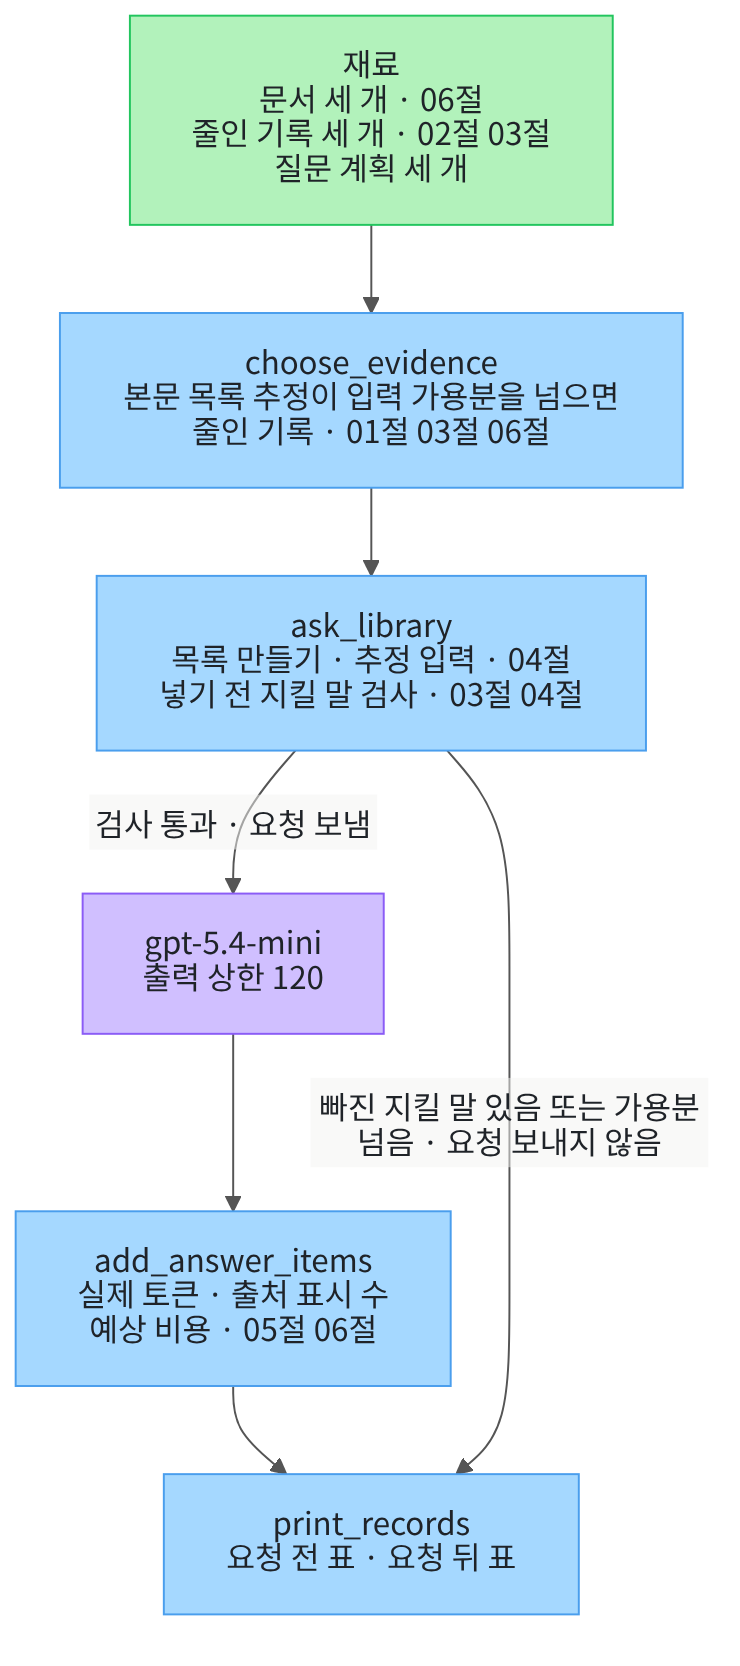

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01~06절과 같은 패키지 판을 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3" "tiktoken==0.14.0"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.8.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.8.0`, `tiktoken: 0.14.0` 등 여섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

두 가지를 불러옵니다. 토큰 수를 세는 라이브러리 tiktoken과, 모델 객체를 만드는 함수입니다.
06절과 달리 이 실습은 파일을 쓰지 않으므로 모듈 `json`·`hashlib`·`time`은 불러오지 않습니다.

In [2]:
# 토큰 수를 세는 라이브러리와 모델 객체를 만드는 함수를 불러옵니다
import tiktoken

from langchain.chat_models import init_chat_model

06절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


출력 예약분과 여유분은 01~06절과 같은 120과 40으로 담습니다. 이 두 값은 실행 1과 실행 2에서 바꾸지 않습니다.
모델 객체는 06절처럼 출력 예약분을 출력 상한(`max_tokens`)으로 주어 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 두 실행에서 같게 둘 출력 예약분·여유분을 담고, 출력 예약분을 출력 상한으로 준 모델을 준비합니다
output_reserve = 120
safety_margin = 40
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=output_reserve,
)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)
print("출력 상한(max_tokens):", model.max_tokens)

출력 예약분: 120
여유분: 40
모델 이름: gpt-5.4-mini
temperature: 0.0
출력 상한(max_tokens): 120


**결과 읽기** — 출력 줄은 `출력 예약분: 120`, `여유분: 40`, `모델 이름: gpt-5.4-mini`입니다.
끝의 두 줄은 `temperature: 0.0`과 `출력 상한(max_tokens): 120`입니다. 이것으로 준비가 끝났습니다.

이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장과 출력 토큰 수가 달라질 수 있습니다.
Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 실습 주제 — 도서관 안내 질문 세 개에 예산표와 지킬 말 검사 붙이기

미르시립도서관 안내 창구에 질문 세 개가 들어왔다고 봅니다. 휴관일, 대출 연장, 회원 주차 요금 질문입니다.
프로그램은 질문마다 06절처럼 목록에서 고른 출처의 본문을 엽니다.

본문 목록의 추정 입력이 01절 입력 가용분을 넘으면, 03절처럼 사람이 줄여 둔 기록을 대신 넣습니다.
넣기 전에는 04절 After처럼 넣을 글을 지킬 말로 검사합니다. 빠진 지킬 말이 있으면 요청을 보내지 않고 그 사실을 요청 기록에 남깁니다.

02절에서 주차 기록에는 원문의 추가 요금이 없다고 적었습니다. 이번 주차 질문은 그 추가 요금까지 묻습니다.

실행 1은 수업 예산 600, 실행 2는 수업 예산 300으로 같은 세 질문을 처리합니다. 두 실행에서 바꾸는 값은 수업 예산 하나입니다.
질문·문서·줄인 기록·지킬 말·모델 설정은 05절처럼 같게 둔 조건입니다.
02절 기록 파일, 04절 혼란·충돌 목록, 05절 긴 측정 입력은 이번 실습에서 쓰지 않습니다.

## 3. 재료 만들기 — 글과 문서 세 개

페르소나와 과업 명세는 02~06절과 글자까지 같습니다. 문서 세 개의 본문도 06절과 같은 글입니다.
E01 문서 2쪽 이용 시간, 3쪽 자료 대출, 5쪽 찾아오시는 길입니다. 토큰 수는 6절에서 함수를 정의한 뒤 셉니다.

실행 전에 예상합니다. 세 본문 가운데 자료 대출 본문이 가장 길 것입니다.

In [5]:
# 02~06절과 같은 페르소나·과업 명세와, 06절과 같은 문서 세 개의 본문을 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 출처를 [E01 p.2]처럼 적으세요."
hours_text = "평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6시까지 문을 엽니다.\n"
hours_text = hours_text + "매주 월요일은 정기 휴관일입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다."
loan_text = "회원 한 사람이 한 번에 빌릴 수 있는 자료는 도서 7권과 영상 자료 2점입니다. 대출 기간은 도서 14일, 영상 자료 7일입니다.\n"
loan_text = loan_text + "대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있습니다. "
loan_text = loan_text + "연장은 반납 예정일 전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다.\n"
loan_text = loan_text + "정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내에서만 열람할 수 있고 대출되지 않습니다."
way_text = "주소는 미르시 중앙동 도서관로 12입니다. 지하철 미르선 중앙역 3번 출구에서 걸어서 5분이며, 시내버스 12·34·56번이 도서관 앞에 정차합니다.\n"
way_text = way_text + "주차장은 80면이며 회원은 최초 2시간 무료, 이후 30분마다 500원입니다. 장애인 주차 구역 5면과 전기차 충전기 2기가 있습니다."
print("본문 글자 수(이용 시간·자료 대출·찾아오시는 길):", len(hours_text), len(loan_text), len(way_text))

본문 글자 수(이용 시간·자료 대출·찾아오시는 길): 138 224 159


**결과 읽기** — 출력 줄은 `본문 글자 수(이용 시간·자료 대출·찾아오시는 길): 138 224 159`입니다. 예상대로 자료 대출 본문이 가장 깁니다.
찾아오시는 길 본문 둘째 줄에는 「이후 30분마다 500원」이라는 추가 요금이 있습니다.

06절과 같은 코드로 문서 세 개와 목록을 만듭니다. 목록 한 줄은 출처 표시, 제목, 한 줄 설명입니다.
사람은 이 목록을 보고 질문마다 열 출처를 고릅니다. 고른 출처는 4절 질문 계획에 적습니다.

In [6]:
# 06절과 같은 코드로 문서 세 개에 출처·제목·한 줄 설명·본문을 붙이고, 본문을 뺀 목록을 만듭니다
documents = [
    {"출처": "E01 p.2", "제목": "2. 이용 시간", "설명": "매주 월요일은 정기 휴관일입니다.", "내용": hours_text},
    {"출처": "E01 p.3", "제목": "4. 자료 대출", "설명": "도서는 7권까지 14일 동안 대출할 수 있습니다.", "내용": loan_text},
    {"출처": "E01 p.5", "제목": "12. 찾아오시는 길", "설명": "회원은 최초 2시간 무료입니다.", "내용": way_text},
]
catalog = []
for document in documents:
    line_text = document["제목"] + ": " + document["설명"]
    catalog.append({"출처": document["출처"], "내용": line_text})
print("목록:")
for item in catalog:
    print("[" + item["출처"] + "] " + item["내용"])

목록:
[E01 p.2] 2. 이용 시간: 매주 월요일은 정기 휴관일입니다.
[E01 p.3] 4. 자료 대출: 도서는 7권까지 14일 동안 대출할 수 있습니다.
[E01 p.5] 12. 찾아오시는 길: 회원은 최초 2시간 무료입니다.


**결과 읽기** — 라벨 줄 `목록:` 아래 세 줄은 06절 목록과 같습니다.
첫 줄은 `[E01 p.2] 2. 이용 시간: 매주 월요일은 정기 휴관일입니다.`입니다.
셋째 줄은 `[E01 p.5] 12. 찾아오시는 길: 회원은 최초 2시간 무료입니다.`입니다.

목록 줄은 06절에서 본 것처럼 본문을 고르는 데 쓰고, 답의 근거로 넣지 않습니다.

## 4. 재료 만들기 — 줄인 기록과 질문 계획

본문이 입력 가용분을 넘을 때 대신 넣을 줄인 기록 세 개를 담습니다. 휴관 기록과 대출 기록은 03절, 주차 기록은 02절과 글자까지 같습니다.
세 기록의 키는 02절 기록과 같은 `출처`·`기관`·`주제`·`내용`입니다.

실행 전에 예상합니다. 주차 기록 줄에는 추가 요금이 없을 것입니다.

In [7]:
# 03절 휴관·대출 기록과 02절 주차 기록을 줄인 기록으로 담습니다
closure_note = {"출처": "E01 p.2", "기관": "미르시립도서관", "주제": "휴관", "내용": "매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다."}
loan_note = {"출처": "E01 p.3", "기관": "미르시립도서관", "주제": "대출", "내용": "회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다."}
parking_note = {"출처": "E01 p.5", "기관": "미르시립도서관", "주제": "주차", "내용": "회원은 최초 2시간 무료입니다."}
short_notes = [closure_note, loan_note, parking_note]
print("줄인 기록(출처 | 주제 | 내용):")
for note in short_notes:
    print(note["출처"], "|", note["주제"], "|", note["내용"])

줄인 기록(출처 | 주제 | 내용):
E01 p.2 | 휴관 | 매주 월요일은 정기 휴관일이고 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.
E01 p.3 | 대출 | 회원 한 사람의 도서 대출 기준은 7권·14일이며, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다.
E01 p.5 | 주차 | 회원은 최초 2시간 무료입니다.


**결과 읽기** — 라벨 줄 아래 세 줄의 마지막은 `E01 p.5 | 주차 | 회원은 최초 2시간 무료입니다.`입니다.
예상대로 주차 기록에는 원문의 「이후 30분마다 500원」이 없습니다. 02절에서 사실 하나만 한 문장으로 옮겨 적은 기록이기 때문입니다.

질문마다 계획을 딕셔너리 하나로 적습니다. 키는 `이름`, `질문`, `출처`, `지킬 말`, `줄인 기록`입니다.
키 `출처`에는 사람이 3절 목록을 보고 고른 출처를 적습니다. 06절 `selected_source`와 같은 일입니다.

휴관 질문과 지킬 말은 03·04절, 대출 연장 질문은 03·06절과 같습니다. 대출 연장의 지킬 말은 06절 연장 조건 세 개입니다.
주차 질문과 지킬 말은 이번 실습에서 새로 적습니다. 지킬 말은 E01 5쪽 원문에서 무료 시간과 추가 요금을 골랐습니다.

In [8]:
# 질문마다 이름·질문·목록에서 고른 출처·지킬 말·줄인 기록을 딕셔너리 하나로 적습니다
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
loan_question = "미르시립도서관에서 빌린 도서의 대출 기간을 연장할 수 있나요?"
parking_question = "미르시립도서관에 회원이 차를 세우면 몇 시간 무료이고, 그 뒤에는 요금이 얼마인가요?"
plans = [
    {"이름": "휴관", "질문": closure_question, "출처": "E01 p.2", "지킬 말": ["월요일", "법정 공휴일", "화요일"], "줄인 기록": closure_note},
    {"이름": "대출 연장", "질문": loan_question, "출처": "E01 p.3", "지킬 말": ["예약이 없는 경우", "1회", "7일 연장"], "줄인 기록": loan_note},
    {"이름": "주차", "질문": parking_question, "출처": "E01 p.5", "지킬 말": ["2시간", "30분마다 500원"], "줄인 기록": parking_note},
]
print("질문 계획(이름 | 출처 | 지킬 말):")
for plan in plans:
    print(plan["이름"], "|", plan["출처"], "|", plan["지킬 말"])

질문 계획(이름 | 출처 | 지킬 말):
휴관 | E01 p.2 | ['월요일', '법정 공휴일', '화요일']
대출 연장 | E01 p.3 | ['예약이 없는 경우', '1회', '7일 연장']
주차 | E01 p.5 | ['2시간', '30분마다 500원']


**결과 읽기** — 라벨 줄 아래 세 줄은 `휴관 | E01 p.2 | ['월요일', '법정 공휴일', '화요일']`로 시작합니다.
둘째 줄은 `대출 연장 | E01 p.3 | ['예약이 없는 경우', '1회', '7일 연장']`입니다.
셋째 줄은 `주차 | E01 p.5 | ['2시간', '30분마다 500원']`입니다.

질문마다 목록 하나를 따로 만들어 보내므로, 03절 나누기처럼 한 요청에는 한 업무의 자료만 들어갑니다.

## 5. 기록 장치 — 검사 함수와 요청 기록표

요청마다 남길 요청 기록을 만드는 함수와, 요청 기록을 표로 출력하는 함수를 준비합니다.
먼저 03절 함수 `find_missing_words()`를 같은 코드로 정의합니다. 글 하나와 말 목록을 받아, 글에 없는 말만 목록으로 반환합니다.
이 함수는 넣기 전 검사와 답 검사에 모두 씁니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [9]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다(03절과 같은 코드)
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

05절 함수 `count_marks()`도 같은 코드로 정의합니다. 답 글에 출처 표시가 몇 번 들어 있는지 셉니다.
과업 명세가 문장마다 출처를 적게 했으므로, 두 문장 답이면 표시가 두 번일 것으로 봅니다. 이 셀은 출력이 없습니다.

In [10]:
# 답 글에 출처 표시가 몇 번 들어 있는지 세어 반환하는 함수를 정의합니다(05절과 같은 코드)
def count_marks(answer_text, mark):
    pieces = answer_text.split(mark)
    mark_count = len(pieces) - 1
    return mark_count

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

Ch 7 08절 함수 `estimate_openai_cost()`도 05·06절과 같은 코드로 정의합니다. 사용량 딕셔너리로 요청 한 번의 예상 비용(달러)을 계산합니다.
기본값은 Ch 6 06절에서 확인한 mini 요금입니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [11]:
# 사용량과 세 요금(기본값 mini 요금)으로 요청 한 번의 예상 비용(달러)을 계산하는 함수를 정의합니다(Ch 7 08절·05·06절과 같은 코드)
def estimate_openai_cost(usage, input_rate=0.75, cached_input_rate=0.075, output_rate=4.50):
    if usage is None:
        return None
    # 캐시 입력 키가 없으면 할인 없이 모두 입력 요금으로 계산합니다
    details = usage.get("input_token_details", {})
    cache_read = details.get("cache_read", 0)
    normal_input = usage["input_tokens"] - cache_read
    input_cost = normal_input * input_rate + cache_read * cached_input_rate
    output_cost = usage["output_tokens"] * output_rate
    price_unit = 1000000
    return (input_cost + output_cost) / price_unit

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청을 보낸 뒤 요청 기록 한 줄에 답 쪽 값을 더하는 함수를 새로 정의합니다. 06절 `make_design_record()`와 05절 `make_length_record()`를 합친 모양입니다.
인자는 요청 기록 딕셔너리, 응답 객체, 넣은 근거 하나, 지킬 말 목록입니다.

더하는 키는 `답`, `실제 입력 토큰 수`, `출력 토큰 수`, `끝난 이유`, `예상 비용(달러)`, `출처 표시 수`, `답에서 빠진 지킬 말`입니다.
Ch 7 08절 `add_cost_items()`처럼 받은 딕셔너리에 키를 더해 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [12]:
# 요청 기록 한 줄에 토큰 수·끝난 이유·예상 비용·출처 표시 수·답에서 빠진 지킬 말을 더해 반환하는 함수를 정의합니다
def add_answer_items(record, run_response, evidence, words):
    run_usage = run_response.usage_metadata
    run_cost = estimate_openai_cost(run_usage)
    record["답"] = run_response.text
    record["실제 입력 토큰 수"] = run_usage["input_tokens"]
    record["출력 토큰 수"] = run_usage["output_tokens"]
    record["끝난 이유"] = run_response.response_metadata["finish_reason"]
    record["예상 비용(달러)"] = round(run_cost, 6)
    # 05절: 넣은 근거의 출처 표시 수를 세고, 03절 함수로 답에 없는 지킬 말을 모읍니다
    record["출처 표시 수"] = count_marks(run_response.text, "[" + evidence["출처"] + "]")
    record["답에서 빠진 지킬 말"] = find_missing_words(run_response.text, words)
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청 기록 목록을 받아 표 두 개를 출력하는 함수를 정의합니다. 요청 전 표에는 모든 요청 기록의 넣은 자료·추정 입력·넣기 전 검사·요청 여부가 나옵니다.
요청 뒤 표에는 「보냄」인 요청 기록만 나오고, 마지막 줄에 예상 비용 합계를 출력합니다.

반복문은 이미 만든 요청 기록을 출력만 하고, 요청을 보내지 않습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [13]:
# 요청 기록 목록을 받아 요청 전 표·요청 뒤 표·예상 비용 합계를 출력하는 함수를 정의합니다
def print_records(records):
    print("요청 전 표(질문 | 넣은 자료 | 추정 입력 | 넣기 전 빠진 지킬 말 | 요청):")
    for record in records:
        print(record["질문"], "|", record["넣은 자료"], "|", record["추정 입력"], "|", record["넣기 전 빠진 지킬 말"], "|", record["요청"])
    print("요청 뒤 표(질문 | 실제 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 출처 표시 수 | 답에서 빠진 지킬 말 | 예상 비용(달러)):")
    total_cost = 0
    for record in records:
        if record["요청"] == "보냄":
            total_cost = total_cost + record["예상 비용(달러)"]
            print(record["질문"], "|", record["실제 입력 토큰 수"], "|", record["출력 토큰 수"], "|", record["끝난 이유"], "|",
                  record["출처 표시 수"], "|", record["답에서 빠진 지킬 말"], "|", record["예상 비용(달러)"])
    print("예상 비용 합계(달러):", round(total_cost, 6))

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 6. 조립 — 본문 열기와 요청 함수

01절 함수 `input_budget()`을 같은 코드로 정의합니다. 수업 예산에서 출력 예약분과 여유분을 빼 입력 가용분을 반환합니다.
실행 1·2 셀에서 수업 예산만 바꿔 이 함수를 부릅니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [14]:
# 수업 예산에서 출력 예약분과 여유분을 빼, 입력에 쓸 수 있는 토큰 수를 반환하는 함수를 정의합니다(01절과 같은 코드)
def input_budget(total_budget, output_reserve, safety_margin):
    available = total_budget - output_reserve - safety_margin
    return available

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

요청 전에 토큰 수를 셀 함수 `count_tokens()`도 01절과 같은 코드로 정의합니다. 규칙 객체 `encoding`을 읽어 글 하나의 토큰 수를 반환합니다.
이 셀은 규칙 객체를 만들고 함수를 정의만 하므로 출력이 없습니다.

In [15]:
# 01절처럼 모델의 토큰화 규칙을 불러오고, 글 하나의 토큰 수를 반환하는 함수를 정의합니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")


def count_tokens(text):
    token_ids = encoding.encode(text)
    return len(token_ids)

**결과 읽기** — 규칙 객체를 만들고 함수를 정의만 하는 셀이라 출력이 없습니다.

06절 함수 `open_document()`를 같은 코드로 정의합니다. 문서 목록과 출처 글을 받아, 출처가 같은 문서를 반환합니다.
목록에 없는 출처면 `None`을 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [16]:
# 문서 목록과 출처 글을 받아, 출처가 같은 문서를 찾아 반환하는 함수를 정의합니다(06절과 같은 코드)
def open_document(document_list, source):
    for document in document_list:
        if document["출처"] == source:
            return document
    return None

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

04절 함수 `build_notes_messages()`를 같은 코드로 정의합니다. 기록 목록과 질문으로 Ch 7 모양의 메시지 목록을 만듭니다.
06절처럼 문서 본문도 키 `출처`와 `내용`이 있어 같은 함수에 넣을 수 있습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [17]:
# 기록 목록과 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다(04절과 같은 코드)
def build_notes_messages(notes, question):
    evidence_text = ""
    for note in notes:
        evidence_text = evidence_text + "[" + note["출처"] + "] " + note["내용"] + "\n"
    user_text = evidence_text + "\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

조립하기 전에, 요청 없이 질문마다 예산표를 봅니다. 본문을 넣은 목록과 줄인 기록을 넣은 목록의 추정 입력을 셉니다.
줄인 기록에서 빠진 지킬 말도 함께 봅니다. 페르소나와 과업 명세의 토큰 수는 이름 `shared_tokens`에 담아 뒤 함수에서도 씁니다.

실행 전에 예상합니다. 대출 연장 본문 목록은 06절 고른 입력처럼 217이고, 대출 기록 목록은 03·06절처럼 128일 것입니다.

In [18]:
# 요청 전에 질문마다 본문 목록·줄인 기록 목록의 추정 입력과, 줄인 기록에서 빠진 지킬 말을 봅니다(요청 없음)
shared_tokens = count_tokens(persona_text) + count_tokens(task_text)
print("페르소나 + 과업 명세 토큰 수:", shared_tokens)
print("요청 전 예산표(질문 | 본문 목록 추정 입력 | 줄인 기록 목록 추정 입력 | 줄인 기록에서 빠진 지킬 말):")
for plan in plans:
    document = open_document(documents, plan["출처"])
    body_messages = build_notes_messages([document], plan["질문"])
    note_messages = build_notes_messages([plan["줄인 기록"]], plan["질문"])
    body_estimate = shared_tokens + count_tokens(body_messages[2][1])
    note_estimate = shared_tokens + count_tokens(note_messages[2][1])
    note_missing = find_missing_words(plan["줄인 기록"]["내용"], plan["지킬 말"])
    print(plan["이름"], "|", body_estimate, "|", note_estimate, "|", note_missing)

페르소나 + 과업 명세 토큰 수: 55
요청 전 예산표(질문 | 본문 목록 추정 입력 | 줄인 기록 목록 추정 입력 | 줄인 기록에서 빠진 지킬 말):
휴관 | 184 | 136 | []
대출 연장 | 217 | 128 | []
주차 | 197 | 103 | ['30분마다 500원']


**결과 읽기** — 첫 줄은 `페르소나 + 과업 명세 토큰 수: 55`로 03~06절과 같습니다.
라벨 줄 아래 세 줄은 `휴관 | 184 | 136 | []`, `대출 연장 | 217 | 128 | []`, `주차 | 197 | 103 | ['30분마다 500원']`입니다.

예상대로 대출 연장은 217과 128입니다. 세 본문 목록은 모두 01절 입력 가용분 440 안에 듭니다.
줄인 기록 목록은 본문 목록보다 48~94토큰 짧습니다. 그러나 주차 기록에는 지킬 말 `30분마다 500원`이 빠져 있습니다.
이 표는 요청 전에 사람이 코드로 센 값이라, 실행할 때마다 같습니다.

이제 근거를 고르는 함수를 정의합니다. 함수 `choose_evidence()`는 질문 계획 하나와 입력 가용분을 받습니다.
06절처럼 고른 출처의 본문을 열고, 본문 목록의 추정 입력을 셉니다. 추정 입력이 입력 가용분을 넘으면 03절 줄인 기록으로 바꿉니다.

반환하는 값은 넣을 근거와 그 종류(「본문」 또는 「줄인 기록」) 두 개입니다. Ch 7 07절 `parse_json_answer()`처럼 튜플로 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [19]:
# 질문 계획 하나와 입력 가용분으로, 넣을 근거(본문 또는 줄인 기록)와 그 종류를 튜플로 반환하는 함수를 정의합니다
def choose_evidence(plan, available):
    # 06절: 사람이 목록에서 고른 출처의 본문을 먼저 엽니다
    document = open_document(documents, plan["출처"])
    body_messages = build_notes_messages([document], plan["질문"])
    body_estimate = shared_tokens + count_tokens(body_messages[2][1])
    evidence = document
    evidence_kind = "본문"
    # 01·03절: 본문 목록이 입력 가용분을 넘으면 사람이 줄여 둔 기록으로 바꿉니다
    if body_estimate > available:
        evidence = plan["줄인 기록"]
        evidence_kind = "줄인 기록"
    return evidence, evidence_kind

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

마지막으로 조립 함수 `ask_library()`를 정의합니다. 질문 계획 하나와 입력 가용분으로 요청 기록 한 줄을 만듭니다. 줄마다 주석에 가져온 절을 적었습니다.

먼저 근거를 고르고 메시지 목록과 추정 입력을 만듭니다. 넣을 근거에서 빠진 지킬 말을 찾고, 요청 기록의 키 `요청`에는 「보내지 않음」을 먼저 담습니다.
빠진 지킬 말이 없고 추정 입력이 입력 가용분 안일 때만 요청을 보냅니다. 그때 키 `요청`을 「보냄」으로 바꾸고 답 쪽 값을 더합니다.

함수 안에서 바깥 이름 `model`과 `shared_tokens`를 읽습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [20]:
# 질문 계획 하나와 입력 가용분으로 근거를 고르고, 두 조건을 지킬 때만 요청을 보내 요청 기록 한 줄을 반환하는 함수를 정의합니다
def ask_library(plan, available):
    # 06·01·03절: 본문을 열고, 입력 가용분을 넘으면 줄인 기록으로 바꿉니다
    evidence, evidence_kind = choose_evidence(plan, available)
    # 04절: 근거 하나와 질문으로 목록을 만들고(03절처럼 질문마다 목록 하나), 01절처럼 추정 입력을 셉니다
    messages = build_notes_messages([evidence], plan["질문"])
    estimate = shared_tokens + count_tokens(messages[2][1])
    # 03·04절: 넣을 근거를 지킬 말로 먼저 검사합니다
    missing_words = find_missing_words(evidence["내용"], plan["지킬 말"])
    # 요청 전 값을 한 줄 딕셔너리로 담고, 키 요청에는 「보내지 않음」을 먼저 적습니다
    record = {"질문": plan["이름"], "넣은 자료": evidence_kind, "추정 입력": estimate, "넣기 전 빠진 지킬 말": missing_words, "요청": "보내지 않음"}
    # 빠진 지킬 말이 없고 추정 입력이 입력 가용분 안일 때만 보냅니다
    if missing_words == [] and estimate <= available:
        record["요청"] = "보냄"
        run_response = model.invoke(messages)
        record = add_answer_items(record, run_response, evidence, plan["지킬 말"])
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 7. 실행 1 — 수업 예산 600

실행 1은 01~06절과 같은 수업 예산 600으로 입력 가용분을 구하고, 질문 세 개를 차례로 처리합니다.
요청은 반복문 안의 `ask_library()`가 보내고, 반복문은 요청 기록만 목록에 모읍니다. 표는 반복이 끝난 뒤 출력합니다.

실행 전에 예상합니다. 입력 가용분은 440이고, 6절 예산표의 세 본문 목록 184·217·197은 모두 그 안에 듭니다.
그래서 세 질문 모두 본문을 넣고, 넣기 전 검사도 통과해 요청을 3번 보낼 것입니다.

In [21]:
# 실행 1: 수업 예산 600으로 입력 가용분을 구하고, 질문 세 개를 차례로 처리합니다(요청은 많아야 3번)
total_budget = 600
available = input_budget(total_budget, output_reserve, safety_margin)
run1_records = []
for plan in plans:
    run1_record = ask_library(plan, available)
    run1_records.append(run1_record)
print("수업 예산:", total_budget)
print("입력 가용분:", available)
print_records(run1_records)

수업 예산: 600
입력 가용분: 440
요청 전 표(질문 | 넣은 자료 | 추정 입력 | 넣기 전 빠진 지킬 말 | 요청):
휴관 | 본문 | 184 | [] | 보냄
대출 연장 | 본문 | 217 | [] | 보냄
주차 | 본문 | 197 | [] | 보냄
요청 뒤 표(질문 | 실제 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 출처 표시 수 | 답에서 빠진 지킬 말 | 예상 비용(달러)):
휴관 | 198 | 52 | stop | 1 | ['법정 공휴일'] | 0.000382
대출 연장 | 231 | 104 | stop | 2 | [] | 0.000641
주차 | 211 | 30 | stop | 1 | [] | 0.000293
예상 비용 합계(달러): 0.001316


**결과 읽기** — 첫 두 줄은 `수업 예산: 600`과 `입력 가용분: 440`입니다.
요청 전 표 라벨 줄 아래 세 줄은 `휴관 | 본문 | 184 | [] | 보냄`, `대출 연장 | 본문 | 217 | [] | 보냄`, `주차 | 본문 | 197 | [] | 보냄`입니다.
예상대로 세 질문 모두 본문을 넣고 요청을 보냈습니다.

요청 뒤 표 라벨 줄 아래 첫 줄은 `휴관 | 198 | 52 | stop | 1 | ['법정 공휴일'] | 0.000382`입니다.
나머지 두 줄은 `대출 연장 | 231 | 104 | stop | 2 | [] | 0.000641`과 `주차 | 211 | 30 | stop | 1 | [] | 0.000293`입니다.
마지막 줄은 `예상 비용 합계(달러): 0.001316`입니다.

세 목록 모두 실제 입력이 추정 입력보다 14 많았습니다. 01~06절의 메시지 3개 목록에서 본 차이와 같습니다.
세 답 모두 끝난 이유는 stop이었습니다. 휴관 답에서만 지킬 말 `법정 공휴일`이 빠졌습니다.

넣은 본문에는 이 말이 있었으므로, 넣기 전 검사를 통과해도 답에서는 빠질 수 있습니다.
휴관·주차 답의 출처 표시가 한 번인 까닭은 다음 셀의 답 글에서 봅니다.

세 요청의 답 글을 출력합니다. 「보냄」인 요청 기록만 골라 출력하고, 요청은 다시 보내지 않습니다.

In [22]:
# 실행 1에서 보낸 요청의 답 글을 출력합니다
for record in run1_records:
    if record["요청"] == "보냄":
        print(record["질문"], "답:")
        print(record["답"])

휴관 답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]
대출 연장 답:
네, 대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장할 수 있으며, 반납 예정일 전에 앱·홈페이지·전화(032-000-1998)로 신청합니다. [E01 p.3]  
다만 정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내 열람만 가능하고 대출되지 않습니다. [E01 p.3]
주차 답:
회원은 최초 2시간 무료이며, 이후에는 30분마다 500원입니다. [E01 p.5]


**결과 읽기** — 라벨 줄 `휴관 답:` 아래 답은 한 줄에 두 문장이고, 끝에만 `[E01 p.2]`가 붙었습니다.
첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`이고, 본문의 「법정 공휴일에도 휴관」은 없습니다.
둘째 문장은 `공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다.`입니다. 왜 한 조건을 빼고 적었는지는 이번 실행으로 알 수 없습니다.

라벨 줄 `대출 연장 답:` 아래 첫 줄은 연장 조건과 신청 방법을 한 문장에 담았습니다.
둘째 줄은 `다만 정기간행물 최신호`로 시작하는, 대출되지 않는 자료 이야기입니다. 이 문장도 자료 대출 본문에 있는 글입니다.

라벨 줄 `주차 답:` 아래 답은 `회원은 최초 2시간 무료이며, 이후에는 30분마다 500원입니다. [E01 p.5]` 한 문장입니다.
한 문장 답이라 출처 표시도 한 번입니다. 추가 요금은 넣은 본문에 있던 글이고, 답에도 들어갔습니다.
실행마다 답 문장과 출력 토큰 수가 달라질 수 있습니다.

## 8. 실행 2 — 수업 예산 300

실행 2는 수업 예산 하나만 600에서 300으로 바꿉니다. 질문·문서·줄인 기록·지킬 말·모델 설정과 조립 함수는 실행 1과 같습니다.

실행 전에 예상합니다. 입력 가용분은 `300 - 120 - 40`으로 140입니다. 세 본문 목록 184·217·197은 모두 140을 넘습니다.
그래서 세 질문 모두 줄인 기록으로 바뀌고, 추정 입력은 136·128·103일 것입니다. 셋 다 140 안입니다.

휴관·대출 연장은 요청을 보낼 것입니다. 주차는 줄인 기록에 「30분마다 500원」이 없어 보내지 않을 것입니다.

In [23]:
# 실행 2: 수업 예산만 300으로 바꿔 입력 가용분을 구하고, 같은 질문 세 개를 차례로 처리합니다(요청은 많아야 3번)
total_budget = 300
available = input_budget(total_budget, output_reserve, safety_margin)
run2_records = []
for plan in plans:
    run2_record = ask_library(plan, available)
    run2_records.append(run2_record)
print("수업 예산:", total_budget)
print("입력 가용분:", available)
print_records(run2_records)

수업 예산: 300
입력 가용분: 140
요청 전 표(질문 | 넣은 자료 | 추정 입력 | 넣기 전 빠진 지킬 말 | 요청):
휴관 | 줄인 기록 | 136 | [] | 보냄
대출 연장 | 줄인 기록 | 128 | [] | 보냄
주차 | 줄인 기록 | 103 | ['30분마다 500원'] | 보내지 않음
요청 뒤 표(질문 | 실제 입력 토큰 수 | 출력 토큰 수 | 끝난 이유 | 출처 표시 수 | 답에서 빠진 지킬 말 | 예상 비용(달러)):
휴관 | 150 | 66 | stop | 2 | [] | 0.000409
대출 연장 | 142 | 59 | stop | 2 | [] | 0.000372
예상 비용 합계(달러): 0.000781


**결과 읽기** — 첫 두 줄은 `수업 예산: 300`과 `입력 가용분: 140`입니다.
요청 전 표 라벨 줄 아래 앞의 두 줄은 `휴관 | 줄인 기록 | 136 | [] | 보냄`과 `대출 연장 | 줄인 기록 | 128 | [] | 보냄`입니다.
셋째 줄은 `주차 | 줄인 기록 | 103 | ['30분마다 500원'] | 보내지 않음`입니다. 예상대로 세 질문 모두 줄인 기록으로 바뀌었고, 주차만 요청을 보내지 않았습니다.

요청 뒤 표에는 보낸 두 요청 기록만 나옵니다. 두 줄은 `휴관 | 150 | 66 | stop | 2 | [] | 0.000409`와 `대출 연장 | 142 | 59 | stop | 2 | [] | 0.000372`입니다.
마지막 줄은 `예상 비용 합계(달러): 0.000781`입니다. 실행 2의 휴관 답에서는 빠진 지킬 말이 없었습니다.

주차 줄인 기록 목록의 추정 입력 103은 입력 가용분 140 안이었습니다. 예산표만 보면 보낼 수 있는 목록이었습니다.
넣기 전 지킬 말 검사가 추가 요금이 빠진 것을 찾아 요청을 막았습니다. 06절 7절에서 본 것처럼 예산표는 길이만 봅니다.

실행 2에서 보낸 요청의 답 글을 출력합니다.

In [24]:
# 실행 2에서 보낸 요청의 답 글을 출력합니다
for record in run2_records:
    if record["요청"] == "보냄":
        print(record["질문"], "답:")
        print(record["답"])

휴관 답:
미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다. [E01 p.2] 공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다. [E01 p.2]
대출 연장 답:
네, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다. [E01 p.3]  
회원 한 사람의 도서 대출 기준은 7권·14일입니다. [E01 p.3]


**결과 읽기** — 라벨 줄 `휴관 답:` 아래 답은 한 줄에 두 문장이고, 문장마다 끝에 `[E01 p.2]`가 붙었습니다.
첫 문장은 `미르시립도서관의 정기 휴관일은 매주 월요일이며, 법정 공휴일에도 휴관합니다.`입니다. 실행 1 답에 없던 말이 들어갔습니다.
둘째 문장은 `공휴일이 월요일과 겹치면 다음 화요일도 휴관합니다.`입니다. 03절 휴관 기록의 마지막 부분과 같은 글입니다.

라벨 줄 `대출 연장 답:` 아래 첫 줄은 `네, 다른 이용자의 예약이 없는 경우에만 1회 7일 연장할 수 있습니다. [E01 p.3]`입니다.
둘째 줄은 `회원 한 사람의 도서 대출 기준은 7권·14일입니다. [E01 p.3]`입니다. 줄인 기록에 없던 신청 방법과 대출되지 않는 자료는 이번 답에 없었습니다.

주차 질문은 요청을 보내지 않았으므로 답이 없습니다. 줄인 기록을 그대로 보냈다면 어떤 답이 왔을지는 이번에 확인하지 않았습니다.

## 9. 두 실행 비교

질문마다 실행 1·2 요청 기록을 한 줄에 나란히 출력합니다. 두 목록은 같은 순서로 질문을 처리했습니다.
그래서 `range(len(plans))`로 같은 번호의 요청 기록을 꺼냅니다.
값 두 개가 나란히 있으면 앞이 실행 1, 뒤가 실행 2입니다.

요청을 보내지 않은 요청 기록에는 답 쪽 키가 없습니다. 그래서 딕셔너리 메서드 `get(키, 기본값)`으로 꺼내고, 키가 없으면 `-`를 출력합니다.
실행 전에 예상합니다. 넣은 자료는 세 질문 모두 본문에서 줄인 기록으로 바뀌고, 주차 줄만 요청이 달라질 것입니다.

In [25]:
# 질문마다 실행 1·2의 넣은 자료·추정 입력·요청·실제 입력 토큰 수·답에서 빠진 지킬 말을 나란히 출력합니다
print("질문 | 넣은 자료(1 2) | 추정 입력(1 2) | 요청(1 2) | 실제 입력 토큰 수(1 2) | 답에서 빠진 지킬 말(1 2)")
for index in range(len(plans)):
    first_record = run1_records[index]
    second_record = run2_records[index]
    print(
        plans[index]["이름"], "|", first_record["넣은 자료"], second_record["넣은 자료"], "|",
        first_record["추정 입력"], second_record["추정 입력"], "|", first_record["요청"], second_record["요청"], "|",
        first_record.get("실제 입력 토큰 수", "-"), second_record.get("실제 입력 토큰 수", "-"), "|",
        first_record.get("답에서 빠진 지킬 말", "-"), second_record.get("답에서 빠진 지킬 말", "-"),
    )

질문 | 넣은 자료(1 2) | 추정 입력(1 2) | 요청(1 2) | 실제 입력 토큰 수(1 2) | 답에서 빠진 지킬 말(1 2)
휴관 | 본문 줄인 기록 | 184 136 | 보냄 보냄 | 198 150 | ['법정 공휴일'] []
대출 연장 | 본문 줄인 기록 | 217 128 | 보냄 보냄 | 231 142 | [] []
주차 | 본문 줄인 기록 | 197 103 | 보냄 보내지 않음 | 211 - | [] -


**결과 읽기** — 라벨 줄 아래 첫 줄은 `휴관 | 본문 줄인 기록 | 184 136 | 보냄 보냄 | 198 150 | ['법정 공휴일'] []`입니다.
둘째 줄은 `대출 연장 | 본문 줄인 기록 | 217 128 | 보냄 보냄 | 231 142 | [] []`입니다.
셋째 줄은 `주차 | 본문 줄인 기록 | 197 103 | 보냄 보내지 않음 | 211 - | [] -`입니다.
예상대로 넣은 자료는 세 질문 모두 바뀌었고, 요청이 달라진 줄은 주차뿐입니다.

두 실행 모두 보낸 휴관·대출 연장은 실제 입력이 198에서 150으로, 231에서 142로 줄었습니다. 답에서 빠진 지킬 말은 휴관 실행 1의 `법정 공휴일` 하나였습니다.
입력 토큰 수는 넣은 자료가 정한 값입니다. 출력 토큰 수와 예상 비용은 같은 목록이어도 요청마다 달라집니다.

## 실험 결과 해석

두 실행은 수업 예산 한 값만 달랐습니다. 입력 가용분이 440에서 140으로 줄자, 조립 함수는 세 질문 모두 본문 대신 줄인 기록을 골랐습니다.

실행 2의 휴관과 대출 연장은 줄인 기록에 지킬 말이 모두 있었고, 두 답에도 지킬 말이 모두 들어갔습니다.
두 질문의 실제 입력을 합치면 429에서 292로 137토큰 줄었습니다. 대출 연장 답은 줄인 기록에 없던 신청 방법을 적지 않았습니다.

실행 1의 휴관 답은 넣은 본문에 있던 `법정 공휴일`을 적지 않았습니다. 넣기 전 검사는 넣을 글만 봅니다.
그래서 요청 뒤 답 검사도 함께 봅니다. 한 번 본 결과라, 본문을 넣으면 조건이 빠진다고 말하지 않습니다.

주차는 줄인 기록 목록이 입력 가용분 안이었습니다. 그러나 넣기 전 검사에서 「30분마다 500원」이 빠진 것이 드러나 요청을 보내지 않았습니다.
실행 1에서 본문을 넣은 주차 답에는 추가 요금이 들어갔습니다. 이 조립 함수에서는 예산을 줄이면 본문 대신 줄인 기록이 들어갑니다. 그래서 줄인 기록에 조건이 남았는지 넣기 전에 검사합니다.

예상 비용 합계는 실행 1이 0.001316달러, 실행 2가 0.000781달러였습니다. 실행 2는 요청이 하나 적었고, 두 질문의 출력도 합계 156토큰과 125토큰으로 달랐습니다.
차이 약 0.00054달러 가운데 보내지 않은 주차 요청이 약 0.00029달러입니다.

줄어든 입력 137토큰은 약 0.00010달러, 줄어든 출력 31토큰은 약 0.00014달러입니다. 입력 쪽만 넣은 자료가 정한 값입니다.
06절에서는 같은 목록도 출력이 104토큰과 64토큰으로 달랐습니다. 그래서 이 비용 차이를 모두 예산 탓으로 보지 않습니다.

이 결론은 질문 세 개·모델 하나·예산마다 한 번 보낸 범위입니다. 지킬 말 검사는 목록에 적은 말이 글에 있는지만 봅니다. 답의 뜻은 원문과 나란히 놓고 사람이 확인합니다.

## 정리

- 06절 본문 열기, 01절 예산표, 03절 지킬 말 검사, 05절 요청 기록 함수를 `ask_library()` 하나로 이었습니다.
- 수업 예산 600인 실행 1에서는 세 질문 모두 본문을 넣어 보냈고, 휴관 답에서만 지킬 말 하나가 빠졌습니다.
- 수업 예산만 300으로 줄인 실행 2에서는 세 질문 모두 줄인 기록으로 바뀌었습니다. 추가 요금이 빠진 주차 기록은 넣기 전 검사에서 걸려 요청을 보내지 않았습니다.

이 절로 Ch 8과 Part 2가 끝납니다. 다음 학습인 Ch 9 01절은 같은 E01 문서를 PDF에서 쪽마다 읽습니다.
이 실습에서 사람이 목록을 보고 적던 출처를, Ch 9에서는 검색이 고릅니다.